# Random Forest — último teste predefinido de ONI resumido

**Pergunta:** acrescentar um resumo de ONI melhora a previsão de aumento de casos
em quatro semanas, além do histórico de casos, clima local e sazonalidade?

Comparamos somente três entradas, sem procurar outras janelas:

| Versão | Informação ENSO adicionada |
|---|---|
| Referência | Nenhuma |
| ONI recente | Um valor: ONI de `t−4` |
| Média ONI | Um valor: média das 12 semanas de `t−15` a `t−4` |

As 72 entradas de base (12 semanas × 6 atributos) são idênticas às anteriores.
Cada resumo acrescenta **uma única coluna**, sem repetir ONI na janela.
O alvo, as datas, cinco sementes e limiar 0,5 são mantidos. Selecionamos o número
de árvores pelo F1 de validação, como nas rodadas anteriores. Não avaliamos o teste.


In [1]:
%matplotlib inline
from pathlib import Path
import runpy
from IPython.display import display

current = Path.cwd().resolve()
PROJECT_ROOT = current.parent if current.name == 'experimento_ONI_resumido' else current
api = runpy.run_path(str(PROJECT_ROOT / 'models/avaliar_oni_resumido.py'))


## Protocolo fixo

- Sementes: 42, 123, 2025, 7 e 99; todas entram no resumo.
- Random Forest: 25, 50, 100 e 200 árvores; profundidade 6; folha mínima 2;
  classes balanceadas. Maior F1 na validação; primeiro modelo em empate.
- Base padronizada já ajustada no treino; cada resumo ONI é padronizado somente no treino.
- Métricas principais: F1 e PR-AUC (Average Precision); métricas complementares exportadas.
- Mesmas 451 amostras de treino e 153 de validação; nenhuma amostra neutra é excluída.

O código comum executa preparação, treinamento, validação e exportação. A referência
sem ENSO é repetida para verificar que reproduz a rodada anterior.


sem_ENSO 42 F1: 0.6988


sem_ENSO 123 F1: 0.7059


sem_ENSO 2025 F1: 0.7294


sem_ENSO 7 F1: 0.7317


sem_ENSO 99 F1: 0.716


ONI_recente 42 F1: 0.625


... (5 outputs left out)

ONI_media12 123 F1: 0.6032


ONI_media12 2025 F1: 0.6567


ONI_media12 7 F1: 0.5574


ONI_media12 99 F1: 0.6087


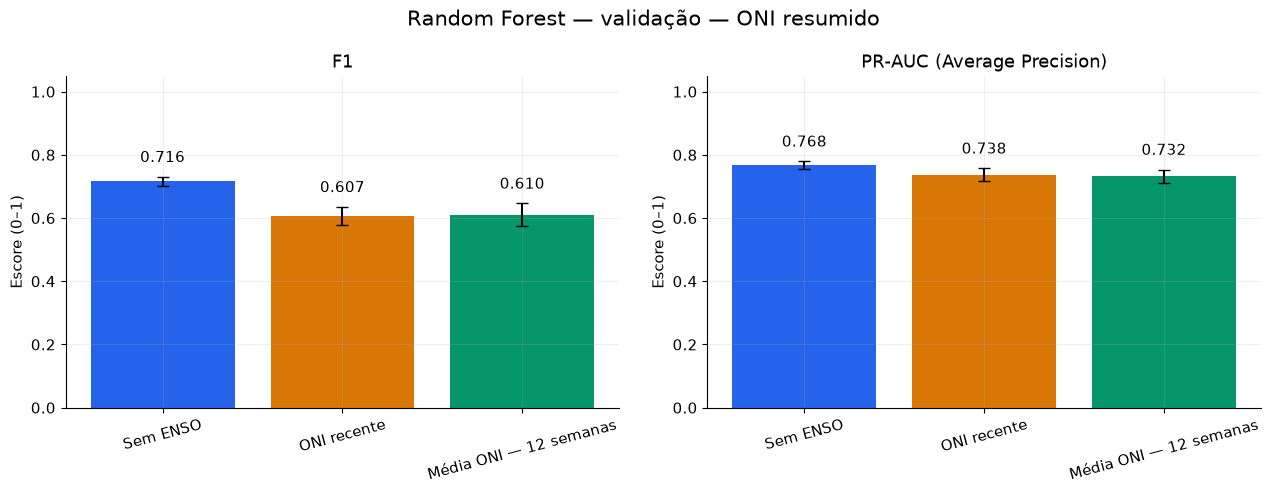

,variant,metric,n_runs,mean,std,min,max
0,sem_ENSO,f1,5,0.7164,0.0144,0.6988,0.7317
1,sem_ENSO,pr_auc,5,0.7680,0.0114,0.7545,0.7834
6,ONI_recente,f1,5,0.6071,0.0283,0.5672,0.6377
7,ONI_recente,pr_auc,5,0.7376,0.0197,0.7141,0.7678
12,ONI_media12,f1,5,0.6102,0.0361,0.5574,0.6567
13,ONI_media12,pr_auc,5,0.7316,0.0218,0.7112,0.7658


In [2]:
summary = api['run_experiment'](PROJECT_ROOT)
display(summary.query("metric in ['f1', 'pr_auc']").round(4))


## Dados e comparações exportados

CSV e JSON: entradas de treino/validação, resumos de ONI por data, previsões por
semente, histórico por quantidade de árvores, métricas e diferenças pareadas.
Checkpoints e scalers em `results/artifacts`; gráficos PNG/SVG em `results/figures`;
JSON consolidado em `results/app_resultados.json`; relatório em `results/relatorio.md`.


In [3]:
import pandas as pd
results = PROJECT_ROOT / 'experimento_ONI_resumido/results'
display(pd.read_csv(results / 'metrics/resumo_diferencas.csv').query("metric in ['f1', 'pr_auc']").round(4))
print('Relatório:', results / 'relatorio.md')
print('JSON:', results / 'app_resultados.json')


,variant,metric,n_pairs,mean_delta,std_delta,positive_deltas,negative_deltas
0,ONI_recente,f1,5,-0.1093,0.0337,0,5
1,ONI_recente,pr_auc,5,-0.0305,0.0224,1,4
6,ONI_media12,f1,5,-0.1062,0.0413,0,5
7,ONI_media12,pr_auc,5,-0.0364,0.0258,1,4


Relatório: /media/lorenzo/SSD/Projetos/ML-Dengue/experimento_ONI_resumido/results/relatorio.md
JSON: /media/lorenzo/SSD/Projetos/ML-Dengue/experimento_ONI_resumido/results/app_resultados.json


## Limite da interpretação

Esta é uma análise exploratória na mesma validação já examinada. A média e o DP
entre sementes não substituem confirmação em outro período ou município. Não
escolhemos novos atrasos ou janelas após ver os resultados. Uma ausência de ganho
nestes testes não demonstra ausência de associação entre ENSO e dengue.
